# Phân tích kết quả thực nghiệm các thuật toán tìm kiếm Bloxorz

**Nguồn dữ liệu:** 'experiments/results.csv' và tệp metadata đi kèm.  
**Mục tiêu:** so sánh BFS, DFS, UCS và A* trên cùng bộ 100 test case; đánh giá khả năng giải, thời gian, bộ nhớ, số trạng thái mở rộng, độ dài lời giải và tổng chi phí.

## 1. Chuẩn bị môi trường và nạp dữ liệu

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd()
candidates = [HERE / "results.csv", HERE / "experiments" / "results.csv", HERE.parent / "results.csv"]
RESULTS_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if RESULTS_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy results.csv. Hãy đặt notebook trong experiments/ "
        "và bảo đảm experiments/results.csv tồn tại. Đã kiểm tra: "
        + ", ".join(str(p) for p in candidates)
    )
METADATA_PATH = RESULTS_PATH.with_name(RESULTS_PATH.stem + "_metadata.json")
df = pd.read_csv(RESULTS_PATH)
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8")) if METADATA_PATH.exists() else {}
numeric_cols = ["search_time_seconds", "peak_memory_mb", "expanded_nodes", "solution_length", "total_cost", "preprocessing_time_seconds"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
ALGORITHM_ORDER = ["BFS", "DFS", "UCS", "A*"]
GROUP_ORDER = ["basic", "fragile", "switches_bridges", "combined", "advanced_switches"]
DIFFICULTY_ORDER = ["easy", "medium", "hard"]
print(f"Số dòng: {len(df):,}")
print(f"Số test case: {df['case_id'].nunique() if 'case_id' in df else 'không xác định'}")
print(f"Thuật toán: {', '.join(a for a in ALGORITHM_ORDER if a in set(df['algorithm']))}")
print(f"Metadata: {'có' if METADATA_PATH.exists() else 'không có'}")
display(df.head())

Số dòng: 400
Số test case: 100
Thuật toán: BFS, DFS, UCS, A*
Metadata: có


,run_id,case_id,group,difficulty,source_level,algorithm,status,search_time_seconds,peak_memory_mb,expanded_nodes,solution_length,total_cost,preprocessing_time_seconds,error
0,20261022T142018Z,BXN-001,basic,medium,custom_001,BFS,solved,0.066430,0.039784,156,22,26.0,0.000000,NaN
1,20261022T142018Z,BXN-001,basic,medium,custom_001,DFS,solved,0.045127,0.028424,124,65,77.5,0.000000,NaN
2,20261022T142018Z,BXN-001,basic,medium,custom_001,UCS,solved,0.037538,0.029112,150,22,26.0,0.000000,NaN
3,20261022T142018Z,BXN-001,basic,medium,custom_001,A*,solved,0.006031,0.159640,22,22,26.0,0.044263,NaN
4,20261022T142018Z,BXN-002,basic,medium,custom_002,BFS,solved,0.030166,0.030424,181,31,37.0,0.000000,NaN


## 2. Kiểm tra chất lượng và tính đầy đủ của dữ liệu

Trước khi so sánh hiệu năng, cần xác minh số dòng, số test case, thuật toán, trạng thái và tính duy nhất của từng cặp (test case, thuật toán). Với một lần chạy gồm 100 màn và 4 thuật toán, kỳ vọng là 400 dòng.

In [2]:
expected_rows = df["case_id"].nunique() * df["algorithm"].nunique()
quality = pd.DataFrame({
    "Chỉ số": [
        "Số dòng kết quả", "Số test case duy nhất", "Số thuật toán",
        "Số dòng kỳ vọng nếu mỗi cặp chạy đúng một lần",
        "Số bản ghi trùng (case_id, algorithm)",
        "Số giá trị thiếu ở các cột đo chính",
        "Số trạng thái solved", "Số timeout", "Số lỗi"
    ],
    "Giá trị": [
        len(df), df["case_id"].nunique(), df["algorithm"].nunique(), expected_rows,
        int(df.duplicated(["case_id", "algorithm"]).sum()),
        int(df[numeric_cols].isna().sum().sum()),
        int((df["status"] == "solved").sum()), int((df["status"] == "timeout").sum()),
        int((df["status"] == "error").sum())
    ]
})
display(quality)
print("Phân bố trạng thái theo thuật toán:")
display(pd.crosstab(df["algorithm"], df["status"]).reindex(ALGORITHM_ORDER))
if "run_id" in df.columns:
    print("Run ID:", ", ".join(sorted(df["run_id"].dropna().astype(str).unique())))
if metadata:
    print("Thông tin metadata:")
    display(pd.DataFrame({"Trường": list(metadata.keys()), "Giá trị": [str(v) for v in metadata.values()]}))

,Chỉ số,Giá trị
0,Số dòng kết quả,400
1,Số test case duy nhất,100
2,Số thuật toán,4
3,Số dòng kỳ vọng nếu mỗi cặp chạy đúng một lần,400
4,"Số bản ghi trùng (case_id, algorithm)",0
5,Số giá trị thiếu ở các cột đo chính,0
6,Số trạng thái solved,400
7,Số timeout,0
8,Số lỗi,0


Phân bố trạng thái theo thuật toán:


status,solved
algorithm,
BFS,100
DFS,100
UCS,100
A*,100


Run ID: 20261022T142018Z
Thông tin metadata:


,Trường,Giá trị
0,run_id,20261022T142018Z
1,timestamp_utc,2026-10-22T14:20:42.435441+00:00
2,dataset_path,D:\Project_CSAI\Bloxorz_Solver\experiments\tes...
3,dataset_version,2
4,case_count,100
5,algorithms,"['BFS', 'DFS', 'UCS', 'A*']"
6,repeat,1
7,timeout_seconds_per_solver_case,15.0
8,python_version,"3.12.13 (main, Jun 23 2026, 15:23:43) [MSC v.1..."
9,platform,Windows-10-10.0.19045-SP0


## 3. Chuẩn hóa các chỉ số

Các chỉ số thời gian được đổi thêm sang mili giây. Với A*, search_time_seconds **không bao gồm** preprocessing_time_seconds; do đó tạo thêm thời gian tìm kiếm và thời gian tổng quan sát (tìm kiếm + tiền xử lý).

In [3]:
df["is_solved"] = df["status"].eq("solved")
df["search_time_ms"] = df["search_time_seconds"] * 1000
df["preprocessing_time_ms"] = df["preprocessing_time_seconds"].fillna(0) * 1000
df["observed_total_time_ms"] = df["search_time_ms"] + df["preprocessing_time_ms"]
solved_df = df[df["is_solved"]].copy()
algorithm_order = [a for a in ALGORITHM_ORDER if a in set(df["algorithm"])]
group_order = [g for g in GROUP_ORDER if g in set(df["group"])]
difficulty_order = [d for d in DIFFICULTY_ORDER if d in set(df["difficulty"])]
print(f"Tỷ lệ dòng có lời giải: {len(solved_df) / len(df):.1%}" if len(df) else "CSV rỗng.")

Tỷ lệ dòng có lời giải: 100.0%


## 4. Bảng tổng hợp hiệu năng theo thuật toán

Bảng chính gồm số lượt chạy, tỷ lệ giải thành công, thời gian trung bình/trung vị/cực đại, tiền xử lý, tổng thời gian quan sát, bộ nhớ peak, số trạng thái mở rộng, độ dài lời giải và tổng chi phí.

In [4]:
summary_rows = []
for alg in algorithm_order:
    all_runs = df[df["algorithm"] == alg]
    solved = all_runs[all_runs["is_solved"]]
    summary_rows.append({
        "Thuật toán": alg, "Lượt chạy": len(all_runs),
        "Giải thành công": f"{len(solved)}/{len(all_runs)}",
        "Tỷ lệ thành công (%)": 100 * len(solved) / len(all_runs) if len(all_runs) else np.nan,
        "Tìm kiếm TB (ms)": solved["search_time_ms"].mean(),
        "Tìm kiếm trung vị (ms)": solved["search_time_ms"].median(),
        "Tìm kiếm max (ms)": solved["search_time_ms"].max(),
        "Tiền xử lý TB (ms)": all_runs["preprocessing_time_ms"].mean(),
        "Tổng thời gian TB (ms)": solved["observed_total_time_ms"].mean(),
        "Bộ nhớ peak TB (MB)": solved["peak_memory_mb"].mean(),
        "Trạng thái mở rộng TB": solved["expanded_nodes"].mean(),
        "Độ dài lời giải TB": solved["solution_length"].mean(),
        "Tổng chi phí TB": solved["total_cost"].mean()
    })
summary = pd.DataFrame(summary_rows).set_index("Thuật toán")
display(summary.round(4).style.format(precision=4, na_rep="—"))

,Lượt chạy,Giải thành công,Tỷ lệ thành công (%),Tìm kiếm TB (ms),Tìm kiếm trung vị (ms),Tìm kiếm max (ms),Tiền xử lý TB (ms),Tổng thời gian TB (ms),Bộ nhớ peak TB (MB),Trạng thái mở rộng TB,Độ dài lời giải TB,Tổng chi phí TB
Thuật toán,,,,,,,,,,,,
BFS,100,100/100,100.0000,58.5961,55.7600,140.4417,0.0000,58.5961,0.0351,240.3300,24.3200,28.8500
DFS,100,100/100,100.0000,47.9526,45.3921,101.2461,0.0000,47.9526,0.0356,168.4600,76.9400,90.3650
UCS,100,100/100,100.0000,65.1752,58.3348,167.3728,0.0000,65.1752,0.0484,239.4800,24.3200,28.8100
A*,100,100/100,100.0000,10.0547,7.5708,53.9997,45.1540,55.2087,0.1382,26.1900,24.3200,28.8100


## 5. Biểu đồ so sánh hiệu năng

### 5.1. Thời gian tìm kiếm và thời gian tổng quan sát

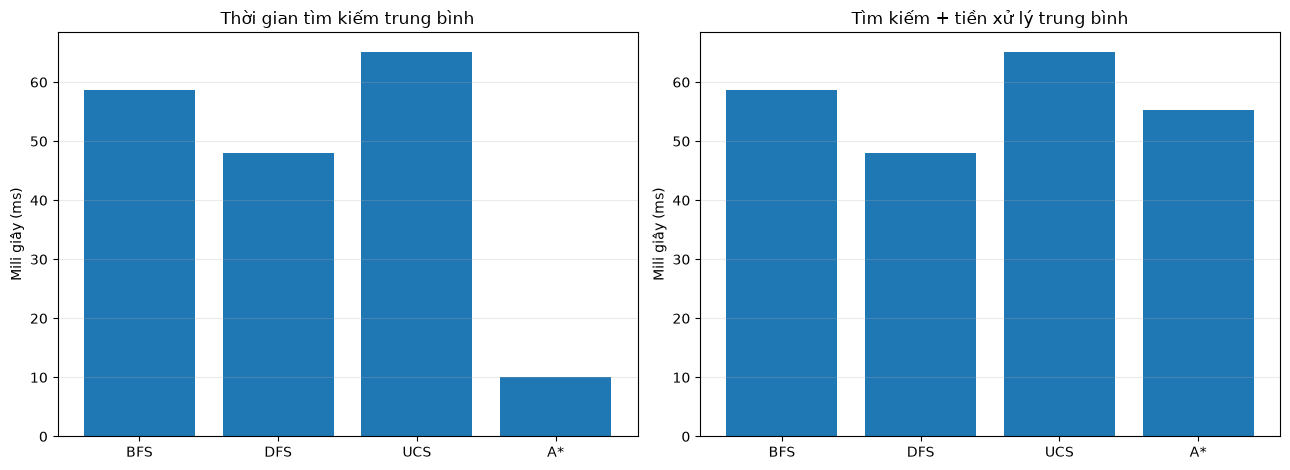

In [5]:
plot_summary = summary.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(plot_summary["Thuật toán"], plot_summary["Tìm kiếm TB (ms)"])
axes[0].set_title("Thời gian tìm kiếm trung bình"); axes[0].set_ylabel("Mili giây (ms)")
axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(plot_summary["Thuật toán"], plot_summary["Tổng thời gian TB (ms)"])
axes[1].set_title("Tìm kiếm + tiền xử lý trung bình"); axes[1].set_ylabel("Mili giây (ms)")
axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### 5.2. Số trạng thái mở rộng

Số trạng thái mở rộng phản ánh lượng công việc tìm kiếm theo bộ đếm của solver. Đây không phải thước đo thời gian tuyệt đối, nhưng giúp giải thích vì sao một thuật toán có thể tìm kiếm nhanh hơn.

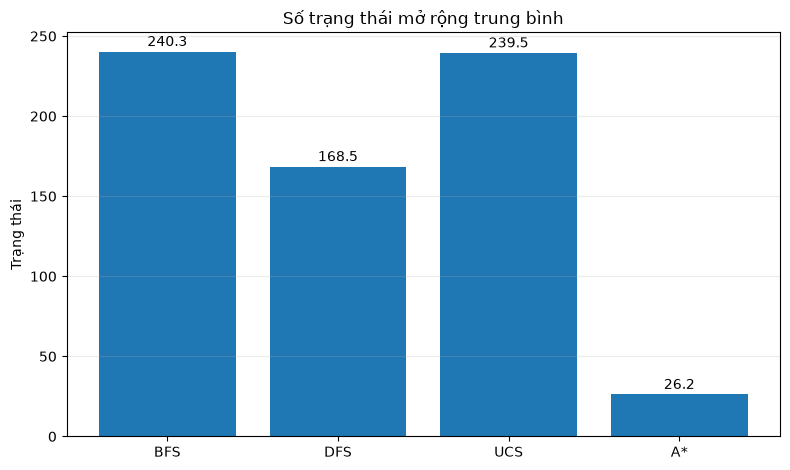

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
vals = [summary.loc[a, "Trạng thái mở rộng TB"] for a in algorithm_order]
bars = ax.bar(algorithm_order, vals)
ax.set_title("Số trạng thái mở rộng trung bình"); ax.set_ylabel("Trạng thái")
ax.grid(axis="y", alpha=0.25)
for bar, val in zip(bars, vals):
    ax.annotate(f"{val:.1f}", (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0,4), textcoords="offset points", ha="center")
plt.tight_layout(); plt.show()

### 5.3. Bộ nhớ peak được theo dõi

peak_memory_mb là bộ nhớ cấp phát Python được tracemalloc theo dõi, không phải tổng RAM của toàn bộ tiến trình.

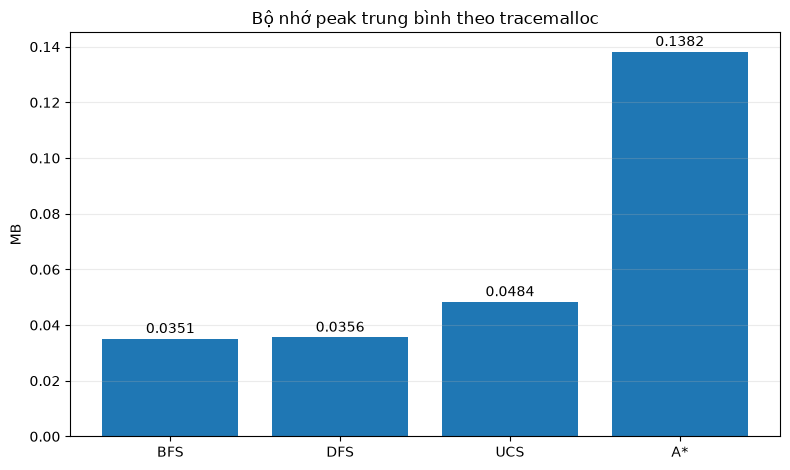

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))
vals = [summary.loc[a, "Bộ nhớ peak TB (MB)"] for a in algorithm_order]
bars = ax.bar(algorithm_order, vals)
ax.set_title("Bộ nhớ peak trung bình theo tracemalloc"); ax.set_ylabel("MB")
ax.grid(axis="y", alpha=0.25)
for bar, val in zip(bars, vals):
    ax.annotate(f"{val:.4f}", (bar.get_x()+bar.get_width()/2, bar.get_height()), xytext=(0,4), textcoords="offset points", ha="center")
plt.tight_layout(); plt.show()

### 5.4. Độ dài lời giải và tổng chi phí

Độ dài lời giải là số hành động; tổng chi phí là tổng Engine.step_cost trên đường đi. Khi chi phí mỗi hành động có thể khác nhau, đường ít bước nhất không nhất thiết có tổng chi phí thấp nhất.

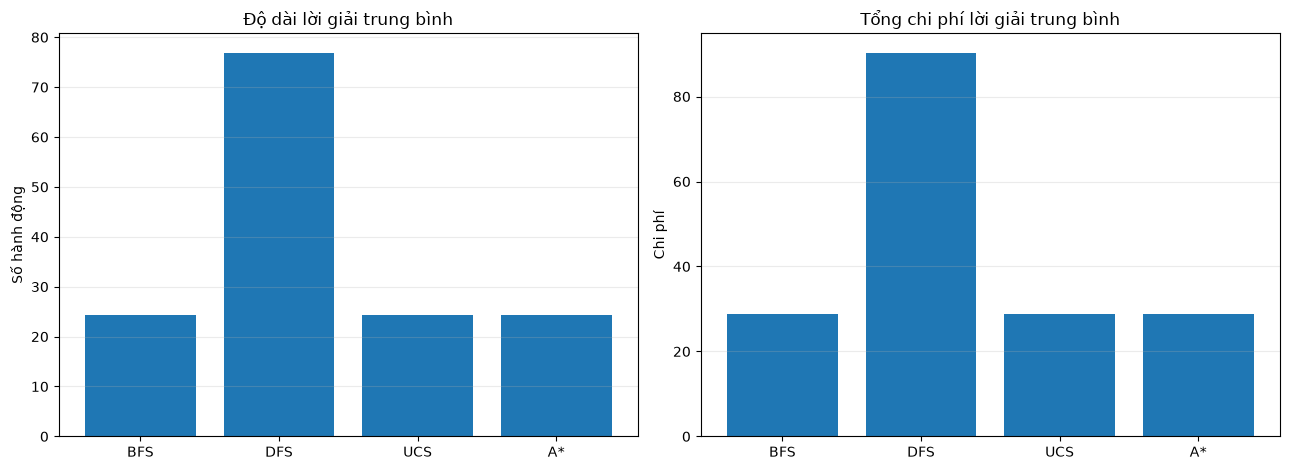

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].bar(algorithm_order, [summary.loc[a, "Độ dài lời giải TB"] for a in algorithm_order])
axes[0].set_title("Độ dài lời giải trung bình"); axes[0].set_ylabel("Số hành động"); axes[0].grid(axis="y", alpha=0.25)
axes[1].bar(algorithm_order, [summary.loc[a, "Tổng chi phí TB"] for a in algorithm_order])
axes[1].set_title("Tổng chi phí lời giải trung bình"); axes[1].set_ylabel("Chi phí"); axes[1].grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()

### 5.5. Phân bố thời gian theo từng màn

Trung bình có thể che khuất những trường hợp chậm bất thường. Boxplot thể hiện trung vị, độ phân tán và các giá trị ngoại lệ.

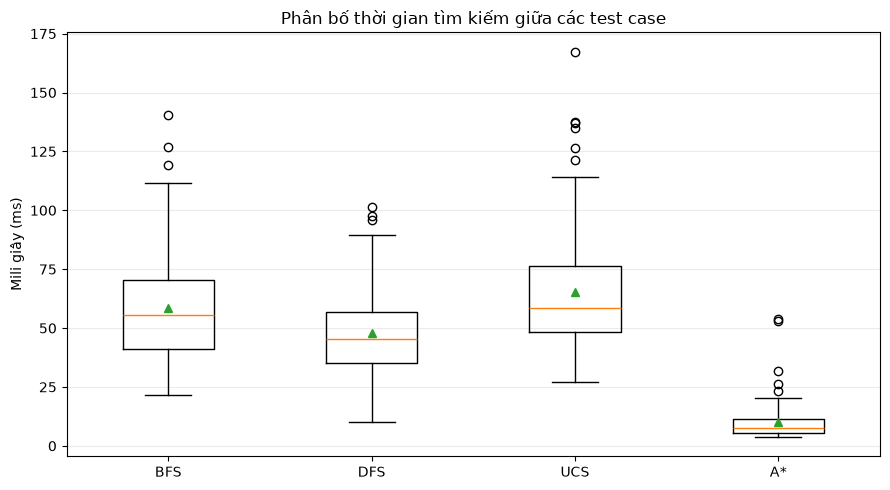

In [9]:
time_data = [
    solved_df.loc[
        solved_df["algorithm"] == a,
        "search_time_ms"
    ].dropna().values
    for a in algorithm_order
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    time_data,
    tick_labels=algorithm_order,
    showmeans=True
)

ax.set_title("Phân bố thời gian tìm kiếm giữa các test case")
ax.set_ylabel("Mili giây (ms)")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 5.6. Quan hệ giữa số trạng thái mở rộng và thời gian

Mỗi điểm là một lượt chạy đã giải thành công. Biểu đồ giúp xem việc mở rộng nhiều trạng thái có đi cùng thời gian tìm kiếm cao hơn hay không.

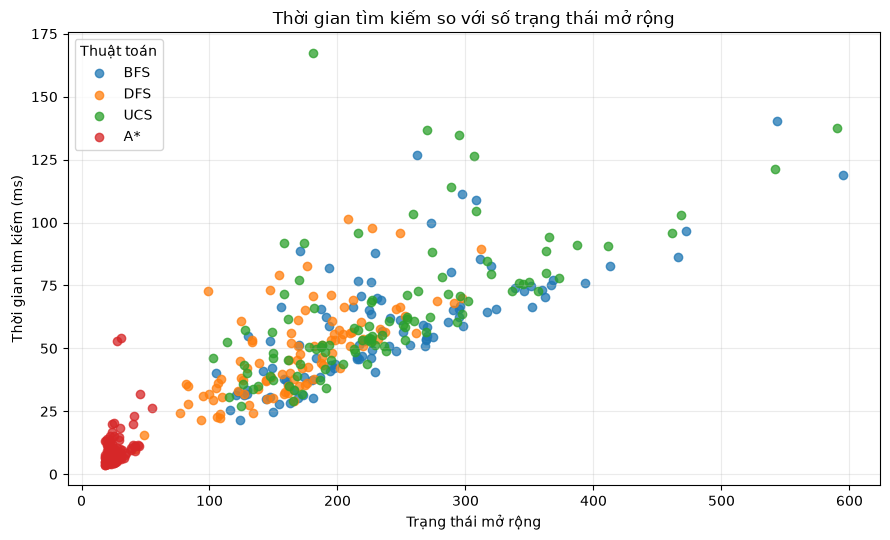

In [10]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for alg in algorithm_order:
    part = solved_df[solved_df["algorithm"] == alg]
    ax.scatter(part["expanded_nodes"], part["search_time_ms"], label=alg, alpha=0.75)
ax.set_title("Thời gian tìm kiếm so với số trạng thái mở rộng")
ax.set_xlabel("Trạng thái mở rộng"); ax.set_ylabel("Thời gian tìm kiếm (ms)")
ax.grid(alpha=0.25); ax.legend(title="Thuật toán"); plt.tight_layout(); plt.show()

## 6. Phân tích theo nhóm cơ chế của bản đồ

Bộ test có năm nhóm: basic, fragile, switches_bridges, combined (mỗi nhóm 25 bản đồ độc lập, cộng các level GUI cùng mechanics) và advanced_switches (11 level GUI có heavy/split switch). Số case thật của từng nhóm nằm trong `design_constraints.cases_per_group` của `test_set.json`.

,group,algorithm,n,search_ms_mean,total_ms_mean,expanded_mean,memory_mb_mean,length_mean,cost_mean
1,basic,BFS,25,59.6400,59.6400,206.52,0.0304,24.28,28.84
2,basic,DFS,25,55.2582,55.2582,164.92,0.0363,72.08,84.74
3,basic,UCS,25,66.0486,66.0486,205.24,0.0407,24.28,28.78
0,basic,A*,25,13.4314,65.9119,26.08,0.1434,24.28,28.78
9,fragile,BFS,25,55.4992,55.4992,192.36,0.0277,23.64,28.06
10,fragile,DFS,25,46.9040,46.9040,150.80,0.0326,72.20,84.84
11,fragile,UCS,25,62.7120,62.7120,192.64,0.0382,23.64,28.04
8,fragile,A*,25,11.6116,63.8725,25.28,0.1373,23.64,28.04
13,switches_bridges,BFS,25,64.7839,64.7839,300.72,0.0446,22.92,27.16
14,switches_bridges,DFS,25,44.4276,44.4276,183.96,0.0385,87.32,102.78


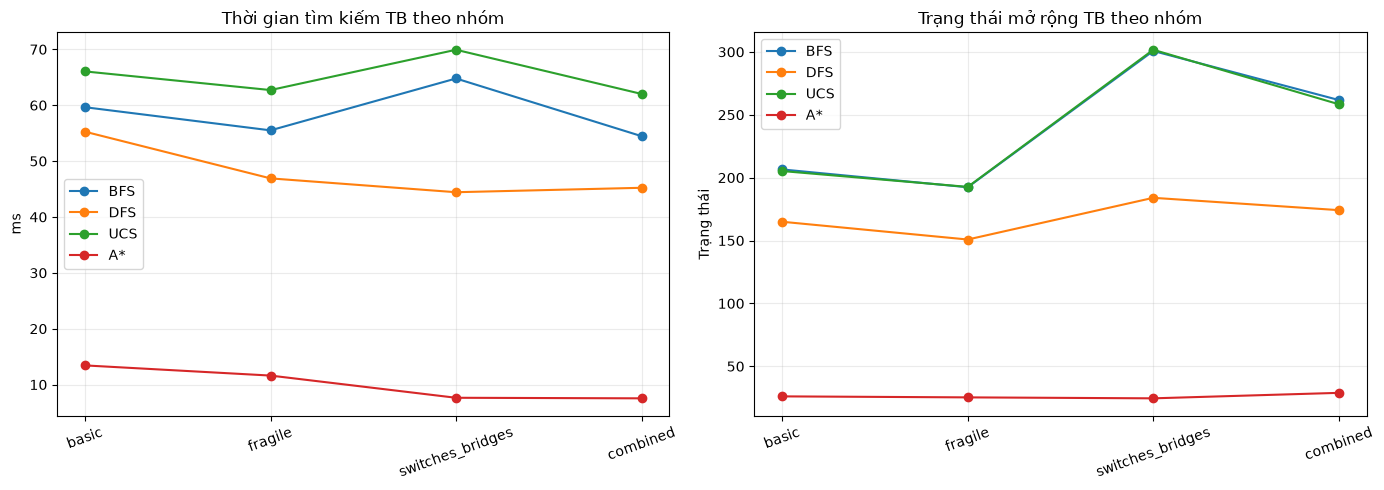

In [11]:
group_metrics = (solved_df.groupby(["group", "algorithm"], observed=True)
    .agg(n=("case_id", "nunique"), search_ms_mean=("search_time_ms", "mean"),
         total_ms_mean=("observed_total_time_ms", "mean"), expanded_mean=("expanded_nodes", "mean"),
         memory_mb_mean=("peak_memory_mb", "mean"), length_mean=("solution_length", "mean"),
         cost_mean=("total_cost", "mean")).reset_index())
group_metrics["group"] = pd.Categorical(group_metrics["group"], categories=group_order, ordered=True)
group_metrics["algorithm"] = pd.Categorical(group_metrics["algorithm"], categories=algorithm_order, ordered=True)
group_metrics = group_metrics.sort_values(["group", "algorithm"])
display(group_metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for alg in algorithm_order:
    part = group_metrics[group_metrics["algorithm"] == alg]
    axes[0].plot(part["group"].astype(str), part["search_ms_mean"], marker="o", label=alg)
    axes[1].plot(part["group"].astype(str), part["expanded_mean"], marker="o", label=alg)
axes[0].set_title("Thời gian tìm kiếm TB theo nhóm"); axes[0].set_ylabel("ms")
axes[1].set_title("Trạng thái mở rộng TB theo nhóm"); axes[1].set_ylabel("Trạng thái")
for ax in axes:
    ax.grid(alpha=0.25); ax.tick_params(axis="x", rotation=20); ax.legend()
plt.tight_layout(); plt.show()

## 7. Phân tích theo nhãn độ khó

Nhãn easy, medium, hard là các tầng gần đúng dựa trên độ dài lời giải BFS đã xác minh khi xây dựng test set. Độ dài lời giải chỉ là một đại diện cho độ khó; branching factor, cấu trúc bản đồ và tương tác ô đặc biệt cũng ảnh hưởng.

,difficulty,algorithm,n,search_ms_mean,total_ms_mean,expanded_mean,length_mean
1,easy,BFS,38,54.7292,54.7292,224.5789,19.5526
2,easy,DFS,38,50.0381,50.0381,170.0000,77.5263
3,easy,UCS,38,62.0604,62.0604,224.2105,19.5526
0,easy,A*,38,7.9675,52.9684,20.8158,19.5526
9,medium,BFS,53,62.6021,62.6021,255.6604,25.5472
10,medium,DFS,53,48.3984,48.3984,173.1321,78.7170
11,medium,UCS,53,69.9108,69.9108,254.4151,25.5472
8,medium,A*,53,10.6677,56.5625,27.6415,25.5472
5,hard,BFS,9,51.3320,51.3320,216.5556,37.2222
6,hard,DFS,9,36.5223,36.5223,134.4444,64.0000


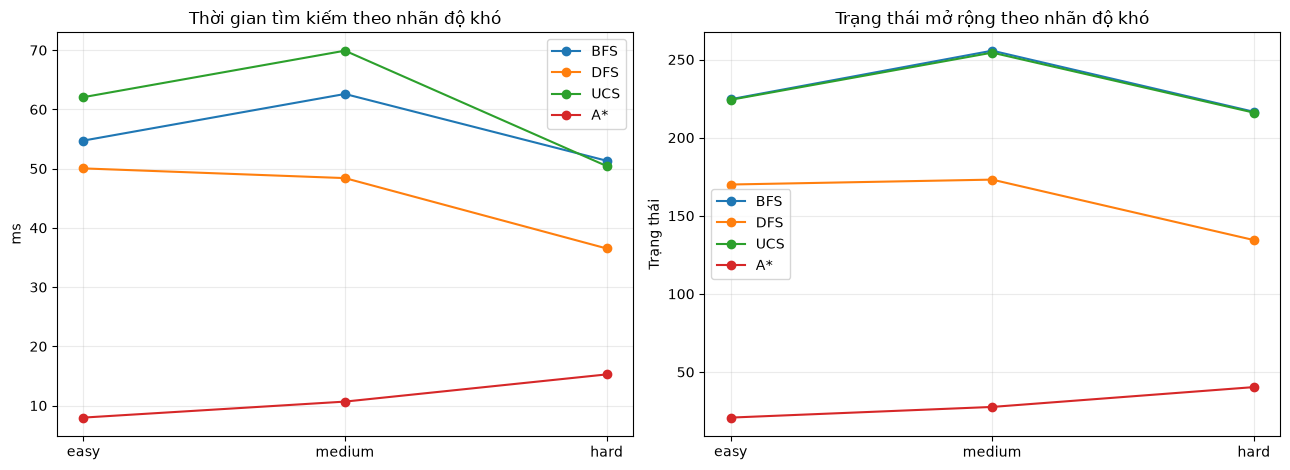

In [12]:
difficulty_metrics = (solved_df.groupby(["difficulty", "algorithm"], observed=True)
    .agg(n=("case_id", "nunique"), search_ms_mean=("search_time_ms", "mean"),
         total_ms_mean=("observed_total_time_ms", "mean"), expanded_mean=("expanded_nodes", "mean"),
         length_mean=("solution_length", "mean")).reset_index())
difficulty_metrics["difficulty"] = pd.Categorical(difficulty_metrics["difficulty"], categories=difficulty_order, ordered=True)
difficulty_metrics["algorithm"] = pd.Categorical(difficulty_metrics["algorithm"], categories=algorithm_order, ordered=True)
difficulty_metrics = difficulty_metrics.sort_values(["difficulty", "algorithm"])
display(difficulty_metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for alg in algorithm_order:
    part = difficulty_metrics[difficulty_metrics["algorithm"] == alg]
    axes[0].plot(part["difficulty"].astype(str), part["search_ms_mean"], marker="o", label=alg)
    axes[1].plot(part["difficulty"].astype(str), part["expanded_mean"], marker="o", label=alg)
axes[0].set_title("Thời gian tìm kiếm theo nhãn độ khó"); axes[0].set_ylabel("ms")
axes[1].set_title("Trạng thái mở rộng theo nhãn độ khó"); axes[1].set_ylabel("Trạng thái")
for ax in axes:
    ax.grid(alpha=0.25); ax.legend()
plt.tight_layout(); plt.show()

## 8. Kiểm tra tính tối ưu và so sánh lời giải theo từng màn

BFS tối ưu số bước khi mỗi hành động có cùng chi phí đơn vị. UCS tối ưu tổng chi phí với chi phí cạnh không âm; A* cũng có thể tối ưu tổng chi phí nếu heuristic đáp ứng điều kiện phù hợp. DFS không đảm bảo tối ưu.

Phần này so sánh từng thuật toán với BFS và so sánh UCS với A* trên cùng case_id. Chênh lệch chi phí dương nghĩa là thuật toán đang xét có chi phí cao hơn BFS; chênh lệch âm nghĩa là thấp hơn BFS.

In [13]:
wide_cost = solved_df.pivot_table(index="case_id", columns="algorithm", values="total_cost", aggfunc="first")
wide_length = solved_df.pivot_table(index="case_id", columns="algorithm", values="solution_length", aggfunc="first")
comparison_rows = []
for alg in [a for a in ["DFS", "UCS", "A*"] if a in wide_cost.columns and "BFS" in wide_cost.columns]:
    common = wide_cost[["BFS", alg]].dropna()
    delta = common[alg] - common["BFS"]
    length_common = wide_length[["BFS", alg]].dropna()
    length_delta = length_common[alg] - length_common["BFS"]
    comparison_rows.append({
        "So với BFS": alg, "Số màn so sánh": len(common),
        "Cùng tổng chi phí": int(np.isclose(delta, 0).sum()),
        "Chi phí cao hơn BFS": int((delta > 1e-9).sum()),
        "Chi phí thấp hơn BFS": int((delta < -1e-9).sum()),
        "Chênh lệch chi phí TB": delta.mean(),
        "Cùng độ dài lời giải": int((length_delta == 0).sum()),
        "Độ dài tăng TB so với BFS": length_delta.mean()
    })
display(pd.DataFrame(comparison_rows).round(4))
if "UCS" in wide_cost.columns and "A*" in wide_cost.columns:
    common_ua = wide_cost[["UCS", "A*"]].dropna()
    print("UCS và A* có cùng tổng chi phí trên", int(np.isclose(common_ua["UCS"], common_ua["A*"]).sum()), "/", len(common_ua), "màn.")
    common_ua_len = wide_length[["UCS", "A*"]].dropna()
    print("UCS và A* có cùng độ dài lời giải trên", int((common_ua_len["UCS"] == common_ua_len["A*"]).sum()), "/", len(common_ua_len), "màn.")

,So với BFS,Số màn so sánh,Cùng tổng chi phí,Chi phí cao hơn BFS,Chi phí thấp hơn BFS,Chênh lệch chi phí TB,Cùng độ dài lời giải,Độ dài tăng TB so với BFS
0,DFS,100,1,99,0,61.515,1,52.62
1,UCS,100,95,0,5,-0.040,100,0.00
2,A*,100,95,0,5,-0.040,100,0.00


UCS và A* có cùng tổng chi phí trên 100 / 100 màn.
UCS và A* có cùng độ dài lời giải trên 100 / 100 màn.


## 9. Các trường hợp đáng chú ý

Bảng sau liệt kê năm màn có thời gian tìm kiếm cao nhất cho từng thuật toán, cùng số trạng thái mở rộng và độ dài lời giải.

In [14]:
top_slow_rows = []
for alg in algorithm_order:
    part = solved_df[solved_df["algorithm"] == alg].nlargest(5, "search_time_seconds")
    for _, r in part.iterrows():
        top_slow_rows.append({
            "Thuật toán": alg, "Case": r["case_id"], "Nhóm": r["group"], "Độ khó": r["difficulty"],
            "Tìm kiếm (ms)": r["search_time_ms"], "Tiền xử lý (ms)": r["preprocessing_time_ms"],
            "Tổng quan sát (ms)": r["observed_total_time_ms"], "Mở rộng": r["expanded_nodes"],
            "Độ dài lời giải": r["solution_length"], "Tổng chi phí": r["total_cost"]
        })
display(pd.DataFrame(top_slow_rows).sort_values(["Thuật toán", "Tìm kiếm (ms)"], ascending=[True, False]).round(4))

,Thuật toán,Case,Nhóm,Độ khó,Tìm kiếm (ms),Tiền xử lý (ms),Tổng quan sát (ms),Mở rộng,Độ dài lời giải,Tổng chi phí
15,A*,BXN-002,basic,medium,53.9997,119.7335,173.7332,31,31,37.0
16,A*,BXN-041,fragile,medium,52.9235,122.2377,175.1612,28,25,30.0
17,A*,BXN-010,basic,hard,31.9649,49.2486,81.2135,46,44,52.5
18,A*,BXN-048,fragile,hard,26.3381,55.7731,82.1112,55,47,56.5
19,A*,BXN-021,basic,medium,23.0858,70.1949,93.2807,41,26,30.5
0,BFS,BXN-051,switches_bridges,medium,140.4417,0.0000,140.4417,543,25,30.0
1,BFS,BXN-038,fragile,medium,126.8619,0.0000,126.8619,262,23,27.5
2,BFS,BXN-070,switches_bridges,medium,119.0668,0.0000,119.0668,595,22,26.0
3,BFS,BXN-040,fragile,medium,111.3893,0.0000,111.3893,297,25,30.0
4,BFS,BXN-028,fragile,medium,108.7984,0.0000,108.7984,308,30,35.5


## 10. Nhận xét tự động từ dữ liệu hiện tại

In [15]:
if len(summary):
    fastest_search = summary["Tìm kiếm TB (ms)"].idxmin()
    fewest_expanded = summary["Trạng thái mở rộng TB"].idxmin()
    lowest_memory = summary["Bộ nhớ peak TB (MB)"].idxmin()
    shortest_path = summary["Độ dài lời giải TB"].idxmin()
    fastest_total = summary["Tổng thời gian TB (ms)"].idxmin()
    best_success = summary["Tỷ lệ thành công (%)"].max()
    best_success_algs = list(summary.index[np.isclose(summary["Tỷ lệ thành công (%)"], best_success)])
    display(Markdown(f'''
- **Thời gian tìm kiếm trung bình thấp nhất:** {fastest_search} ({summary.loc[fastest_search, "Tìm kiếm TB (ms)"]:.3f} ms/lượt).
- **Ít trạng thái mở rộng nhất:** {fewest_expanded} ({summary.loc[fewest_expanded, "Trạng thái mở rộng TB"]:.2f} trạng thái/lượt).
- **Bộ nhớ peak trung bình thấp nhất theo tracemalloc:** {lowest_memory} ({summary.loc[lowest_memory, "Bộ nhớ peak TB (MB)"]:.4f} MB).
- **Độ dài lời giải trung bình thấp nhất:** {shortest_path} ({summary.loc[shortest_path, "Độ dài lời giải TB"]:.2f} hành động).
- **Tổng thời gian quan sát trung bình thấp nhất (tìm kiếm + tiền xử lý):** {fastest_total} ({summary.loc[fastest_total, "Tổng thời gian TB (ms)"]:.3f} ms/lượt).
- **Tỷ lệ thành công cao nhất:** {best_success:.1f}% ({", ".join(best_success_algs)}).
'''))


- **Thời gian tìm kiếm trung bình thấp nhất:** A* (10.055 ms/lượt).
- **Ít trạng thái mở rộng nhất:** A* (26.19 trạng thái/lượt).
- **Bộ nhớ peak trung bình thấp nhất theo tracemalloc:** BFS (0.0351 MB).
- **Độ dài lời giải trung bình thấp nhất:** BFS (24.32 hành động).
- **Tổng thời gian quan sát trung bình thấp nhất (tìm kiếm + tiền xử lý):** DFS (47.953 ms/lượt).
- **Tỷ lệ thành công cao nhất:** 100.0% (BFS, DFS, UCS, A*).


## 11. Điểm mạnh và điểm yếu của từng thuật toán

### BFS (Breadth-First Search)
**Điểm mạnh**
- Tìm lời giải có ít hành động nhất khi mỗi bước là một cạnh cùng độ sâu.
- Dễ dùng làm mốc kiểm chứng độ dài lời giải trên bài toán không trọng số.
- Kết quả tương đối dễ giải thích.

**Điểm yếu**
- Có thể lưu hàng đợi lớn và mở rộng nhiều trạng thái khi độ sâu tăng.
- Không tối ưu tổng chi phí nếu chi phí mỗi hành động khác nhau.
- Có thể kém hiệu quả hơn tìm kiếm có heuristic khi heuristic dẫn đường tốt.

### DFS (Depth-First Search)
**Điểm mạnh**
- Có thể tìm lời giải nhanh nếu nhánh được duyệt sớm dẫn tới đích.
- Thường có frontier nhỏ hơn BFS trong cách cài đặt DFS truyền thống.

**Điểm yếu**
- Không đảm bảo tìm đường ngắn nhất hoặc tổng chi phí thấp nhất.
- Kết quả phụ thuộc mạnh vào thứ tự sinh successor; đường đi có thể dài hơn nhiều.
- Thời gian tốt ở một vài màn không đồng nghĩa ổn định trên các bản đồ khác.

### UCS (Uniform-Cost Search)
**Điểm mạnh**
- Ưu tiên trạng thái có chi phí đường đi tích lũy thấp nhất.
- Phù hợp khi hành động có chi phí không đồng nhất; với chi phí cạnh không âm, có thể tìm lời giải chi phí tối ưu.
- Là mốc so sánh quan trọng cho A* nếu cả hai dùng cùng hàm chi phí.

**Điểm yếu**
- Có thể mở rộng nhiều trạng thái khi chi phí gần đồng đều.
- Hàng đợi ưu tiên tạo thêm chi phí tính toán.
- Trong bộ test nhỏ và thời gian rất ngắn, overhead và nhiễu môi trường có thể ảnh hưởng đáng kể.

### A* (A-star)
**Điểm mạnh**
- Kết hợp chi phí đã đi g(n) với heuristic h(n), giúp tập trung tìm kiếm về phía đích.
- Nếu heuristic đáp ứng điều kiện phù hợp, A* có thể tối ưu tổng chi phí trong khi mở rộng ít trạng thái hơn UCS.
- Số trạng thái mở rộng và thời gian tìm kiếm là các chỉ số quan trọng để đánh giá hiệu quả heuristic.

**Điểm yếu**
- Tốn thời gian tiền xử lý heuristic; cần báo cáo cả thời gian tìm kiếm và thời gian tổng quan sát.
- Bộ nhớ có thể cao hơn do hàng đợi và dữ liệu heuristic.
- Tính tối ưu phụ thuộc tính chất heuristic và cách cài đặt; một bộ test không đủ chứng minh tính tối ưu trong mọi trường hợp.